In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as optimize

speed = np.arange(17, dtype=float)
stopping = np.array([0, 3, 6, 11, 21, 32, 47, 65, 87, 112,
                     140, 171, 204, 241, 282, 325, 376], dtype=float)


def max_absolute_residual(a):
    """Chebyshev (minimax) objective for y = a x^2."""
    return np.max(np.abs(stopping - a * speed**2))


result = optimize.minimize(max_absolute_residual, x0=1.0)
a = result.x[0]
print(f"fitted a = {a:.6f}, max residual = {result.fun:.4f}")


fitted a = 1.445902, max residual = 5.8492


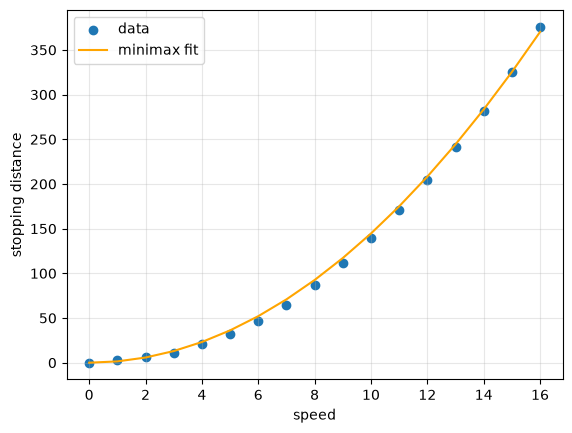

In [2]:
predict = a * speed**2
plt.scatter(speed, stopping, label="data")
plt.plot(speed, predict, color="orange", label="minimax fit")
plt.xlabel("speed")
plt.ylabel("stopping distance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [3]:
# The same minimax idea for the log-linear model y = a x^2.
# Taking logs gives log y = log a + 2 log x.
mask = speed > 0
log_speed = np.log(speed[mask])
log_stopping = np.log(stopping[mask])


def max_log_residual(log_a):
    return np.max(np.abs(log_stopping - (log_a + 2 * log_speed)))


result_log = optimize.minimize(max_log_residual, x0=np.log(1.0))
a_log = np.exp(result_log.x[0])
print(f"fitted a (log model) = {a_log:.6f}, max log residual = {result_log.fun:.4f}")


fitted a (log model) = 1.914854, max log residual = 0.4490


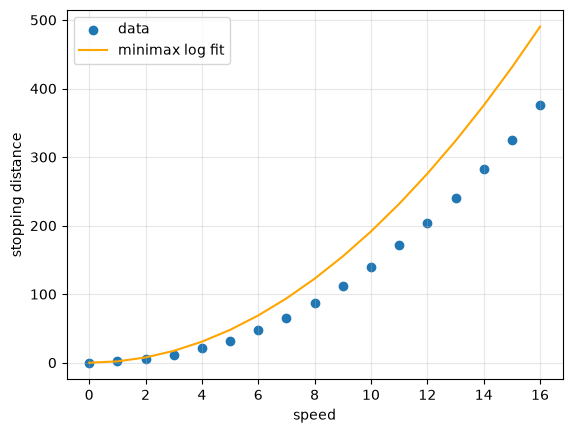

In [4]:
predict_log = a_log * speed**2
plt.scatter(speed, stopping, label="data")
plt.plot(speed, predict_log, color="orange", label="minimax log fit")
plt.xlabel("speed")
plt.ylabel("stopping distance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
